# Week 2: Mechanics and Data Quality
Verify that you can trust the data you downloaded.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

TICKERS = ["TLT", "SHY"]    # my pair: long vs short Treasuries

data = {}
for ticker in TICKERS:
    data[ticker] = pd.read_csv(f"../data/{ticker}.csv", index_col=0, parse_dates=True)
    print(ticker, "saved:", len(data[ticker]), "days")

data["TLT"].tail() #view last 5 rows as an example


TLT saved: 2514 days
SHY saved: 2514 days


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2025-12-24,85.062859,88.029999,88.080002,87.650002,87.760002,25942000
2025-12-26,84.782639,87.739998,88.169998,87.599998,88.099998,26522700
2025-12-29,85.101509,88.070000,88.070000,87.790001,87.949997,29399800
2025-12-30,84.898582,87.860001,88.040001,87.669998,87.739998,25106800
2025-12-31,84.222176,87.160004,87.910004,87.129997,87.680000,36500000


## Visual
Plot three versions of the price for each asset on one chart:

1. **Raw Close**: the price that actually traded that day
2. **Close**: adjusted for splits only
3. **Adj Close**: adjusted for splits and dividends

Yahoo doesn't give you the raw price, because its `Close` is already split-adjusted.
To rebuild it, multiply every price *before* a split by that split's ratio (take the time to learn this code):

    splits = yf.Ticker("TICKER").splits
    splits.index = splits.index.tz_localize(None)
    factor = pd.Series(1.0, index=df.index)
    for date, ratio in splits.items():
        factor[df.index < date] *= ratio
    df["Raw Close"] = df["Close"] * factor

Use `logy=True` when plotting so the lines are readable.

**What to look for:**
- **Splits**: Raw Close drops suddenly while Close and Adj Close don't. If your asset has never split, Raw Close sits exactly on top of Close.
- **Dividends**: Close and Adj Close slowly drift apart. To see this clearly, also plot `df["Adj Close"] / df["Close"]`. It steps up each time a dividend is paid and stays flat at 1.0 for non-payers.

Check what you find against `yf.Ticker("TICKER").actions`, which lists every split and dividend.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

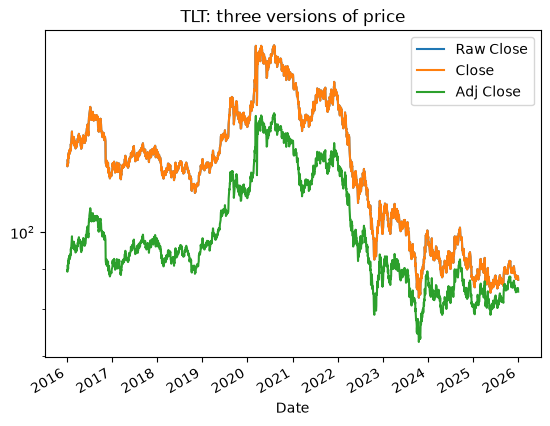

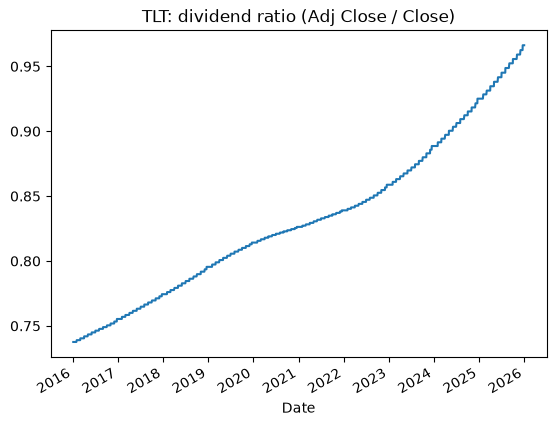

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

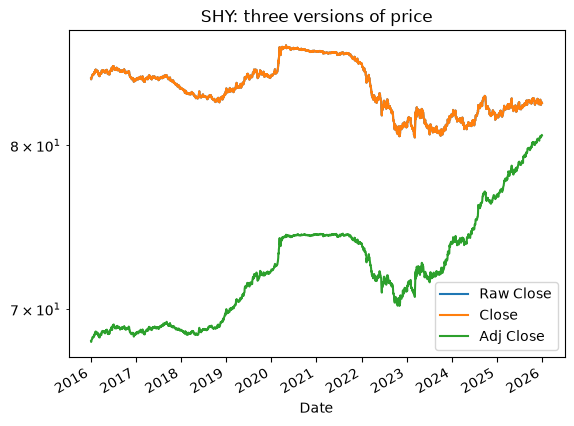

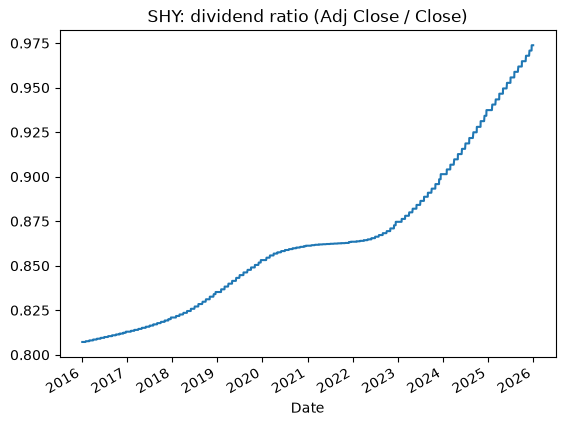

TLT
                           Dividends
Date                                
2025-11-03 00:00:00-05:00      0.325
2025-12-01 00:00:00-05:00      0.321
2025-12-19 00:00:00-05:00      0.342
2026-02-02 00:00:00-05:00      0.332
2026-03-02 00:00:00-05:00      0.301
2026-04-01 00:00:00-04:00      0.345
2026-05-01 00:00:00-04:00      0.315
2026-06-01 00:00:00-04:00      0.336
2026-07-01 00:00:00-04:00      0.318
2026-08-03 00:00:00-04:00      0.330
2026-09-01 00:00:00-04:00      0.315
2026-10-01 00:00:00-04:00      0.312

SHY


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

                           Dividends
Date                                
2025-11-03 00:00:00-05:00      0.263
2025-12-01 00:00:00-05:00      0.249
2025-12-19 00:00:00-05:00      0.255
2026-02-02 00:00:00-05:00      0.250
2026-03-02 00:00:00-05:00      0.223
2026-04-01 00:00:00-04:00      0.247
2026-05-01 00:00:00-04:00      0.243
2026-06-01 00:00:00-04:00      0.243
2026-07-01 00:00:00-04:00      0.238
2026-08-03 00:00:00-04:00      0.251
2026-09-01 00:00:00-04:00      0.244
2026-10-01 00:00:00-04:00      0.241



/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={


In [35]:
for ticker in TICKERS:
    df = data[ticker] # this asset's full price table

    # Rebuild Raw Close by undoing any splits
    splits = yf.Ticker(ticker).splits # split dates and ratios from Yahoo (empty if none)
    splits.index = splits.index.tz_localize(None) # remove timezone so dates match our CSV
    factor = pd.Series(1.0, index=df.index) # start with a factor of 1.0 for every day
    for date, ratio in splits.items():# loop over each (date, ratio) split
        factor[df.index < date] *= ratio # scale up every day before the split
    df["Raw Close"] = df["Close"] * factor # the price that actually traded

    # Chart 1: three versions of price
    df[["Raw Close", "Close", "Adj Close"]].plot(logy=True, title=f"{ticker}: three versions of price")
    plt.show()

    # Chart 2: dividend ratio (steps up each time a dividend is paid)
    div_ratio = df["Adj Close"] / df["Close"] # 1.0 = no dividend adjustment
    div_ratio.plot(title=f"{ticker}: dividend ratio (Adj Close / Close)")
    plt.show()

# Check what we found against Yahoo's list of splits and dividends
for ticker in TICKERS:
    print(ticker)
    print(yf.Ticker(ticker).actions.tail(12))
    print()


## Table
Calculate the **median daily dollar volume** (Close × Volume). Which asset is more liquid?

In [36]:
# Daily Dollar volume = price x shares traded
dollar_vol = pd.DataFrame()
for ticker in TICKERS:
    dollar_vol[ticker] = data[ticker]["Close"] * data[ticker]["Volume"]

median_dv = dollar_vol.median() # Median, not mean, so a few huge-volume days don't distort the result
table = pd.DataFrame({"Median Daily Dollar Volume": median_dv})
median_ratio = median_dv["TLT"] / median_dv["SHY"]
print(f"Median daily dollar volume ratio TLT/SHY = {median_ratio:.1f}x")
table.map("${0:,.0f}".format) # format as dollars with commas and no decimals

Median daily dollar volume ratio TLT/SHY = 7.7x


,Median Daily Dollar Volume
TLT,"$1,772,301,281"
SHY,"$231,093,528"


## Defect checks
Look for missing days, zero-volume days, impossible prices and ticker changes. Then fix what you find in code.

In [47]:
for ticker in TICKERS:
    df = data[ticker]
    print(f" ===== {ticker} =====")

    # 1. Missing values and missing days
    print("NaN values:", df.isna().sum().sum())
    all_weekdays = pd.bdate_range(df.index[0], df.index[-1]) # every Mon-Fri in our range
    missing = all_weekdays.difference(df.index) # weekdays that are not in our data
    print("Missing weekdays:", len(missing))
    # 2. Zero-volume days
    print("Zero-volume days:", (df["Volume"] == 0).sum())
    # 3. Impossible prices 
    prices = df[["Open", "High", "Low", "Close", "Adj Close"]]
    impossible = (
        (prices < 0).any(axis=1)
        | (df["High"] < df["Low"])
        | (df["Close"] > df["High"])
        | (df["Close"] < df["Low"])
    ) 
    print("Impossible price rows:", impossible.sum())
    print()

# Both assets should trade on exactly the same days, so lets check that:
print("Same dates for TLT and SHY:", data["TLT"].index.equals(data["SHY"].index))

# Look at the missing weekdays: are the market holidays?
print(missing.strftime("%Y-%m-%d").tolist())

 ===== TLT =====
NaN values: 0
Missing weekdays: 94
Zero-volume days: 0
Impossible price rows: 0

 ===== SHY =====
NaN values: 0
Missing weekdays: 94
Zero-volume days: 0
Impossible price rows: 0

Same dates for TLT and SHY: True
['2016-01-18', '2016-02-15', '2016-03-25', '2016-05-30', '2016-07-04', '2016-09-05', '2016-11-24', '2016-12-26', '2017-01-02', '2017-01-16', '2017-02-20', '2017-04-14', '2017-05-29', '2017-07-04', '2017-09-04', '2017-11-23', '2017-12-25', '2018-01-01', '2018-01-15', '2018-02-19', '2018-03-30', '2018-05-28', '2018-07-04', '2018-09-03', '2018-11-22', '2018-12-05', '2018-12-25', '2019-01-01', '2019-01-21', '2019-02-18', '2019-04-19', '2019-05-27', '2019-07-04', '2019-09-02', '2019-11-28', '2019-12-25', '2020-01-01', '2020-01-20', '2020-02-17', '2020-04-10', '2020-05-25', '2020-07-03', '2020-09-07', '2020-11-26', '2020-12-25', '2021-01-01', '2021-01-18', '2021-02-15', '2021-04-02', '2021-05-31', '2021-07-05', '2021-09-06', '2021-11-25', '2021-12-24', '2022-01-17', 

| Defect | Asset | What you found | How your code fixed it |
|---|---|---|---|
| Missing days |  TLT & SHY | 94 weekdays with no data; all are NYSE closure (holidays, national days of mourning)| No fix needed: these days never traded. Filling them would create fake 0% returns and understate volatility |
| Zero-volume days | TLT & SHY | 0 days | No fix necessary. However, in case there were, I'd use a guard filter (boolean) to ensure Volume > 0 to remove zero-volume days |
| Impossible prices | TLT & SHY | 0 days| There were no impossible prices. Fix: create a guard filter |
| Ticker changes | TLT & SHY | 0 days | No Ticker Changes. If one had changed, I'd join the old and new ticker histories into one series |

## The Paragraph
> **Document your defect list and explain how your code fixed them.**

The verdict is that both TLT and SHY passed every defect check, so my code did not need to fix anything. Each asset has 2,514 trading days from January 4, 2016 to December 31, 2025, with no missing values, no zero-volume days, no impossible prices, and no ticker changes. The 94 weekdays absent from each file are not missing data; everyone is an NYSE closure, including standard holidays, Good Fridays, and the national days of mourning on December 5, 2018 and January 9, 2025. Both assets share identical dates, and filling those days would only create fake 0% returns and likely understate volatility. If defects had appeared, I'd use `dropna()` for missing values, `Volume > 0` guard filter for zero-volume days, a `~impossible` mask to drop bad price rows, and join old and new histories for any ticker changes.

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 5: data quality"
git push
```